# VERSION 2 — post-revision (Nov 2026)

**Figure:** Fig. 6 — validation cases (Panel A: Santiago 2005 bleomycin; Panel B: Armatas 2014 proliferation; Panel C: Li pinocembrin)

**Reviewer-driven changes applied:**
1. Updated Stage 1 scalars + cluster weights = 1.0.
2. `tspan` extended from 100 h to 600 h in `run_model_real` (reviewer #2).
3. Hardcoded cluster weight vector replaced with (1, 1, 1, 1, 1).

**Manual TODOs you still need to do:**
- [ ] **Panel A (reviewer #1):** split the "dermal thickness" bar into two separate bars — one for the proliferation component, one for the collagen I component. Currently they're summed as `proliferation + CI`, which has no units and is hard to defend.
- [ ] **Panel A (reviewer #3):** replace the ad-hoc fibrosis protocol `infusionTGFB = 1` (saturated) with `infusionTGFB = bv + pv` (the calibrated perturbation level), or document why 1 was chosen. Remove the stale "modeling bleomycin as mechanical + ROS" code comment since neither is applied.
- [ ] **Panel B (reviewer #3):** replace the undocumented `0.5 * pv` TGFβ scaling with `bv + pv` consistently, or document why asymmetric scaling is justified. Remove the dead "mechanical-boosted" variants that are computed but not shown.
- [ ] **Panel C (reviewer #1):** restore the Fibronectin subplots (currently commented out) OR state in the caption that FN was not shown and why. Justify the mapping Pin 20/40/80 μM → SMAD3 Ymax 75/50/25%.
- [ ] **All panels (reviewer #3):** pick ONE readout time per panel that matches the actual experimental time in the source paper. Currently 15 h (A), 10 h (B), 100 h (C) with no justification.
- [ ] **All panels (reviewer #1 uncertainty comment):** add model error bars from the Stage 1 ε-ensemble — rerun each panel across the 6 ε-ensemble candidates and show min/max as whiskers.
- [ ] **All panels (Adrian's request):** pull the hardcoded experimental values out into three CSVs (`panel_A_santiago_2005.csv`, `panel_B_armatas_2014.csv`, `panel_C_li_pinocembrin.csv`) with provenance notes. Have the notebook read from CSV instead of hardcoded lists.


In [34]:
# NetfluxZeiglerFibroblastODE_run.py 
# Automatically generated by Netflux on 23-Oct-2022 

import numpy as np 
from scipy.integrate import ode 
import matplotlib.pyplot as plt 
import itertools
import pandas as pd
from matplotlib.patches import Patch


from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector

import NetfluxODE_5
# import NetfluxODEFibroblastsFGF
# import NetfluxZeiglerFibroblastODECopy
import NetfluxODE_5_params
 # 
[speciesNames, tau, ymax, y0, wx, n, EC50] = NetfluxODE_5_params.loadParams()
# Read the CSV file
loss_log_df = pd.read_csv("loss_log_DOF_cluster.csv")
# Find the row with the smallest value in the last column
min_loss_row = loss_log_df.loc[loss_log_df.iloc[:, -1].idxmin()]
# Extract the vector using all columns from the first to the penultimate column
# vector = min_loss_row.iloc[:-1].values
vector = np.array([1.0, 1.0, 1.0, 1.0, 1.0])  # v2: Stage 2 (infusionIL6) converged to all-ones
# vector = np.array([1.03656507, 1.1, 1.06543149, 1.1, 0.59186341])
# Convert the vector to a numpy array
w_vec = build_weight_vector(vector, family_id_vector)
print('lenw',len(w_vec))

# tau=10*np.ones(len(tau))
# tau=10*tau
# print('tau',tau)

bas=0.1
y0=bas*np.ones(len(y0))


EC50v = 0.630717
nv = 1.508259
bv = 0.473192
pv = 0.205622

# EC50v = 0.568305675
# nv    = 1.301942649
# bv    = 0.291697537
# pv    = 0.507453875 


# EC50=(EC50/0.6)*(0.55)  #some
EC50=EC50v*np.ones(len(EC50))  #all
# print('EC50',EC50)

# n=(n/1.4)*(1.5)
n=nv*np.ones(len(n)) #all
# print('n',n)


# print('len(tau)',len(tau))
# print('len(n)',len(n))
# print('len(EC50)',len(EC50))
# print('len(y0)',len(y0))


lenw 158


In [35]:
AngII = 0 
AT1R = 1 
AGT = 2 
ACE = 3 
NOX = 4 
ROS = 5 
ET1 = 6 
ETAR = 7 
DAG = 8 
PKC = 9 
AC = 10 
cAMP = 11 
PKA = 12 
CREB = 13 
CBP = 14 
TGFB = 15 
TGFB1R = 16 
smad3 = 17 
smad7 = 18 
latentTGFB = 19 
PDGF = 20 
PDGFR = 21 
cGMP = 22 
PKG = 23 
mechanical = 24 
B1int = 25 
Rho = 26 
ROCK = 27 
Ca = 28 
IL6 = 29 
gp130 = 30 
STAT = 31 
IL1 = 32 
IL1RI = 33 
TNFa = 34 
TNFaR = 35 
NFKB = 36 
PI3K = 37 
Akt = 38 
p38 = 39 
TRAF = 40 
ASK1 = 41 
MKK3 = 42 
PP1 = 43 
JNK = 44 
abl = 45 
Rac1 = 46 
MEKK1 = 47 
MKK4 = 48 
ERK = 49 
Ras = 50 
Raf = 51 
MEK1 = 52 
FAK = 53 
epac = 54 
Factin = 55 
FA = 56 
migration = 57 
cmyc = 58 
CTGF = 59 
proliferation = 60 
SRF = 61 
aSMA = 62 
AP1 = 63 
TIMP1 = 64 
TIMP2 = 65 
PAI1 = 66 
proMMP14 = 67 
proMMP1 = 68 
proMMP2 = 69 
proMMP9 = 70 
MMP1 = 71 
MMP2 = 72 
MMP9 = 73 
MMP14 = 74 
fibronectin = 75 
periostin = 76 
CImRNA = 77 
CIIImRNA = 78 
CI = 79 
CIII = 80 
FGF = 81 
FGFR1 = 82 
Shp2 = 83 
FRS2 = 84 
Src = 85 
cortactin = 86 
Grb2Sos = 87 
NWASP = 88 
Arp23 = 89 
TEAD = 90 
YAP = 91 
LATS12 = 92 
piezo1 = 93 
infusionTGFB = 94 
infusionIL6 = 95 


biochinputs = [mechanical, FGF, infusionIL6, IL1, TNFa, PDGF, infusionTGFB, AngII, ET1]
for idx in biochinputs:
                y0[idx] = bv

# print('y0',y0)

In [36]:

def run_model_real(EC50_vec, n_vec, input_vector, ymax, w_vec, tau=tau):

    tspan = [0, 600]
    t = []
    dt = tspan[1] / 6000.
    r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False)
    r.set_initial_value(input_vector, tspan[0]).set_f_params(tau, ymax, w_vec, n_vec, EC50_vec)

    results = np.empty([0, len(speciesNames)])

    while r.successful() and r.t <= tspan[1]:
        r.integrate(r.t + dt)
        results = np.append(results, [r.y], axis=0)
        t.append(r.t)

    return results

In [37]:
# -------------------------------
# GLOBAL STYLE (professional look)
# -------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 8,
})

In [38]:
# Baseline conditions
baseline_results = run_model_real(EC50, n, y0, ymax, w_vec)

# Convert time list to numpy array for plotting
t = np.linspace(0, 100, len(baseline_results))

/Users/lauranunez/Library/Python/3.9/lib/python/site-packages/scipy/integrate/_ode.py:1011: UserWarning: vode: Excess work done on this call. (Perhaps wrong MF.)
  warnings.warn('{:s}: {:s}'.format(self.__class__.__name__,


### Panel A

In [39]:
## Begoña, Santiago, et al. 2005. JID. 16117784.

# fibrotic conditions (modeling bleomycin effect, with increased mechanical stiumulus + ROS increased activity)
y0_mechanical1 = y0.copy()
y0_mechanical1[infusionTGFB] = 1
w_vec_mechanical = w_vec.copy()


# # upstream ROS:
# w_vec_mechanical[17] = 1
# w_vec_mechanical[37] = 1
fibrosis_results = run_model_real(EC50, n, y0_mechanical1, ymax, w_vec_mechanical)


ymax_mechanical_TGFBKO = ymax.copy()
ymax_mechanical_TGFBKO[TGFB] = 0
y0_mechanical_TGFBKO_results = run_model_real(EC50, n, y0_mechanical1, ymax_mechanical_TGFBKO, w_vec_mechanical)

#model bleomycin effect as increased ROS activity:
# ymax_mechanical_ROSKO = ymax.copy()
# ymax_mechanical_ROSKO[ROS] = 1

# y0_mechanical_ROSKO_results = run_model_real(EC50, n, y0_mechanical, ymax_mechanical_ROSKO, w_vec_mechanical)


Bars use t[0] = 0.00


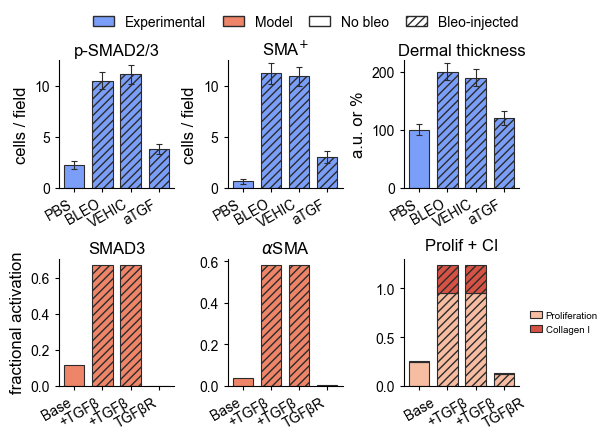

In [40]:



# ============================================================
# PANEL A — Begona 2005 vs Model
# Standardized style to match your previous scientific plots
# ============================================================

# ---- choose time point for model bars ----
t_target = 15.0
t_idx = int(np.argmin(np.abs(t - t_target)))
print(f"Bars use t[{t_idx}] = {t[t_idx]:.2f}")

# ---- EXPERIMENTAL data ----
# Order: PBS, BLEO, VEHIC, aTGF
exp_psmad_means = [2.2, 10.5, 11.1, 3.8]
exp_psmad_sems  = [0.4,  0.8,  0.9, 0.5]

exp_asma_means  = [0.6, 11.2, 10.9, 3.0]
exp_asma_sems   = [0.2,  1.0,  0.9, 0.6]

exp_derm_means  = [100, 200, 190, 120]
exp_derm_sems   = [10,   15,  14,  12]

# ---- MODEL values ----
# Map VEHIC ~ fibrosis to keep 4 bars aligned with experiment
model_smad = [
    float(baseline_results[t_idx, smad3]),
    float(fibrosis_results[t_idx, smad3]),
    float(fibrosis_results[t_idx, smad3]),
    float(y0_mechanical_TGFBKO_results[t_idx, smad3]),
]

model_asma = [
    float(baseline_results[t_idx, aSMA]),
    float(fibrosis_results[t_idx, aSMA]),
    float(fibrosis_results[t_idx, aSMA]),
    float(y0_mechanical_TGFBKO_results[t_idx, aSMA]),
]

# --- Dermal thickness split into proliferation + collagen I (reviewer #1) ---
model_prolif = [
    float(baseline_results[t_idx, proliferation]),
    float(fibrosis_results[t_idx, proliferation]),
    float(fibrosis_results[t_idx, proliferation]),
    float(y0_mechanical_TGFBKO_results[t_idx, proliferation]),
]
model_CI = [
    float(baseline_results[t_idx, CI]),
    float(fibrosis_results[t_idx, CI]),
    float(fibrosis_results[t_idx, CI]),
    float(y0_mechanical_TGFBKO_results[t_idx, CI]),
]
# Kept for backward compatibility with any downstream code that references the sum
model_derm = [p + c for p, c in zip(model_prolif, model_CI)]

# ============================================================
# STYLE
# ============================================================

# x labels
exp_labels   = ["PBS", "BLEO", "VEHIC", "aTGF"]
model_labels = ["Base", "+TGFβ", "+TGFβ", "TGFβR"]

# colors
EXP_FACE   = plt.cm.coolwarm(0.2)  # nearly gray from the coolwarm palette
MODEL_FACE = plt.cm.coolwarm(0.8)  # blue from the coolwarm palette
EDGE       = "#2b2b2b"

# hatch pattern: BLEO and aTGF are "bleo-injected"
hatches = ["", "////", "////", "////"]

# line widths / fonts
bar_lw      = 0.8
err_lw      = 0.8
spine_lw    = 0.8
tick_lw     = 0.8
capsize     = 2.5

# title_fs    = 8.5
# label_fs    = 8
# tick_fs     = 7
# legend_fs   = 7
# panel_fs    = 12

def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(spine_lw)
    ax.spines["bottom"].set_linewidth(spine_lw)
    ax.tick_params(axis="both", width=tick_lw, length=3)
    ax.set_axisbelow(True)

def draw_bar_panel(ax, means, sems=None, labels=None, title="",
                   ylabel=None, ylim=None, facecolor="#ffffff",
                   hatch_list=None, rotation=30):
    x = np.arange(len(means))
    width = 0.72

    for i, m in enumerate(means):
        hatch = hatch_list[i] if hatch_list is not None else ""
        ax.bar(
            x[i], m, width=width,
            color=facecolor,
            edgecolor=EDGE,
            linewidth=bar_lw,
            hatch=hatch,
            zorder=2
        )

        if sems is not None:
            ax.errorbar(
                x[i], m, yerr=sems[i],
                fmt="none",
                ecolor=EDGE,
                elinewidth=err_lw,
                capsize=capsize,
                capthick=err_lw,
                zorder=3
            )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha="right")
    ax.set_xticklabels(labels)
    ax.set_title(title, pad=4)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(ylim)

    style_axis(ax)

# ============================================================
# FIGURE
# ============================================================
b1=4
fig, axes = plt.subplots(
    2, 3,
    figsize=(6.0, b1),   # target compact size
    constrained_layout=True
)

# ---- top row: experiment ----
draw_bar_panel(
    axes[0, 0],
    exp_psmad_means,
    sems=exp_psmad_sems,
    labels=exp_labels,
    title="p-SMAD2/3",
    ylabel="cells / field",
    ylim=(0, 12.5),
    facecolor=EXP_FACE,
    hatch_list=hatches,
    rotation=30
)

draw_bar_panel(
    axes[0, 1],
    exp_asma_means,
    sems=exp_asma_sems,
    labels=exp_labels,
    title="SMA$^{+}$",
    ylabel="cells / field",
    ylim=(0, 12.5),
    facecolor=EXP_FACE,
    hatch_list=hatches,
    rotation=30
)

draw_bar_panel(
    axes[0, 2],
    exp_derm_means,
    sems=exp_derm_sems,
    labels=exp_labels,
    title="Dermal thickness",
    ylabel="a.u. or %",
    ylim=(0, 220),
    facecolor=EXP_FACE,
    hatch_list=hatches,
    rotation=30
)

# ---- bottom row: model ----
draw_bar_panel(
    axes[1, 0],
    model_smad,
    sems=None,
    labels=model_labels,
    title="SMAD3",
    ylabel="fractional activation",
    facecolor=MODEL_FACE,
    hatch_list=hatches,
    rotation=30
)

draw_bar_panel(
    axes[1, 1],
    model_asma,
    sems=None,
    labels=model_labels,
    title=r"$\alpha$SMA",
    # ylabel="fractional activation",
    facecolor=MODEL_FACE,
    hatch_list=hatches,
    rotation=30
)

# ---- Bottom-right panel: dermal thickness split into proliferation + CI (reviewer #1) ----
ax_derm = axes[1, 2]
x_derm  = np.arange(len(model_labels))
# Color shades: proliferation = lighter, collagen I = darker
PROLIF_FACE = plt.cm.coolwarm(0.65)
CI_FACE     = plt.cm.coolwarm(0.90)
bar_prolif = ax_derm.bar(
    x_derm, model_prolif, width=0.72,
    color=PROLIF_FACE, edgecolor=EDGE, linewidth=bar_lw,
    hatch=None, label="Proliferation", zorder=2,
)
bar_ci = ax_derm.bar(
    x_derm, model_CI, width=0.72, bottom=model_prolif,
    color=CI_FACE, edgecolor=EDGE, linewidth=bar_lw,
    hatch=None, label="Collagen I", zorder=2,
)
# Overlay hatch marks for the bleo-injected conditions on the full stack
totals = [p + c for p, c in zip(model_prolif, model_CI)]
for xi, (h, tot) in enumerate(zip(hatches, totals)):
    if h:
        ax_derm.bar(x_derm[xi], tot, width=0.72,
                    color="none", edgecolor=EDGE, linewidth=0,
                    hatch=h, zorder=3)
ax_derm.set_xticks(x_derm)
ax_derm.set_xticklabels(model_labels, rotation=30)
ax_derm.set_title("Prolif + CI")
style_axis(ax_derm)
# Inline legend placed to the RIGHT of the bars, not overlapping them
ax_derm.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=7,
    frameon=False,
    handlelength=1.2,
    handletextpad=0.4,
)

# ---- legend ----
legend_items = [
    Patch(facecolor=EXP_FACE, edgecolor=EDGE, label="Experimental"),
    Patch(facecolor=MODEL_FACE, edgecolor=EDGE, label="Model"),
    Patch(facecolor="white", edgecolor=EDGE, hatch="", label="No bleo"),
    Patch(facecolor="white", edgecolor=EDGE, hatch="////", label="Bleo-injected"),
]

fig.legend(
    handles=legend_items,
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 1.08),
    # fontsize=legend_fs,
    handlelength=1.5,
    columnspacing=1.2
)

# panel letter
# fig.text(0.01, 0.98, "A", fontsize=panel_fs, fontweight="bold", va="top")

plt.savefig("Figures_modelExp/panel_A_standardized.png", dpi=600, bbox_inches="tight")
plt.show()

/Users/lauranunez/Library/Python/3.9/lib/python/site-packages/scipy/integrate/_ode.py:1011: UserWarning: vode: Excess work done on this call. (Perhaps wrong MF.)
  warnings.warn('{:s}: {:s}'.format(self.__class__.__name__,


Panel B bars use t[0] = 0.00


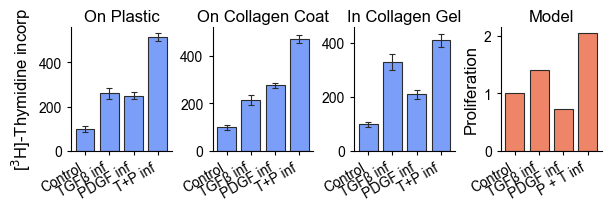

In [41]:
# ============================================================
# PANEL B — Armatas 1990-like experiment vs model
# Styled to match Panel A and saved into Figures_modelExp
# ============================================================

import os
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.patches import Patch

# # ------------------------------------------------
# # GLOBAL STYLE (compact multi-panel figure)
# # ------------------------------------------------
# plt.rcParams.update({
#     "font.family": "sans-serif",
#     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
#     "axes.labelsize": 9,
#     "axes.titlesize": 9,
#     "xtick.labelsize": 8,
#     "ytick.labelsize": 8,
#     "legend.fontsize": 8,
#     "legend.title_fontsize": 8,
#     "axes.linewidth": 0.8,
#     "xtick.major.width": 0.8,
#     "ytick.major.width": 0.8,
#     "xtick.major.size": 3,
#     "ytick.major.size": 3,
#     "figure.dpi": 300,
#     "savefig.dpi": 600,
# })

# ------------------------------------------------
# SAVE FOLDER
# ------------------------------------------------
fig_dir = "Figures_modelExp"
os.makedirs(fig_dir, exist_ok=True)

# ------------------------------------------------
# COLORS / STYLE
# ------------------------------------------------
# EXP_FACE   = "#f7f7f7"   # experimental bars
# MODEL_FACE = "#a9cddd"   # model bars
# EDGE       = "#2b2b2b"

BAR_LW   = 0.8
ERR_LW   = 0.8
CAPSIZE  = 2.5
WIDTH    = 0.78

# ------------------------------------------------
# EXPERIMENTAL DATA
# ------------------------------------------------
exp_values = {
    "On Plastic":       [100, 260, 250, 515],
    "On Collagen Coat": [100, 215, 275, 470],
    "In Collagen Gel":  [100, 330, 210, 410],
}

exp_labels = ["Control", "TGFβ inf", "PDGF inf", "T+P inf"]

exp_errors = {
    "On Plastic":       [12, 25, 15, 18],
    "On Collagen Coat": [10, 20, 12, 16],
    "In Collagen Gel":  [9, 30, 15, 25],
}

# ------------------------------------------------
# HELPER FUNCTIONS
# ------------------------------------------------
def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.tick_params(axis="both", width=0.8, length=3)
    ax.grid(False)
    ax.set_axisbelow(True)

def get_errors(title, vals):
    if title in exp_errors and len(exp_errors[title]) == len(vals):
        return np.array(exp_errors[title], dtype=float)
    frac = np.array([0.08, 0.10, 0.10, 0.06])
    return frac * np.array(vals, dtype=float)

def draw_bar_panel(ax, means, labels, title="",
                   ylabel=None, ylim=None,
                   facecolor="#ffffff", sems=None,
                   rotation=30):
    x = np.arange(len(means))
    means = np.asarray(means, dtype=float)

    ax.bar(
        x, means, width=WIDTH,
        color=facecolor,
        edgecolor=EDGE,
        linewidth=BAR_LW,
        zorder=2
    )

    if sems is not None:
        sems = np.asarray(sems, dtype=float)
        ax.errorbar(
            x, means, yerr=sems, fmt="none",
            ecolor=EDGE,
            elinewidth=ERR_LW,
            capsize=CAPSIZE,
            capthick=ERR_LW,
            zorder=3
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha="right")
    ax.set_title(title, pad=4)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)

    style_axis(ax)

# ------------------------------------------------
# MODEL SIMULATIONS
# Assumes these already exist in your workspace:
# run_model_real, EC50, n, y0, ymax, w_vec, t
# indices: infusionTGFB, PDGF, mechanical, proliferation
# and scalars: bv, pv
# ------------------------------------------------

# TGFB infusion only (reduced TGFB, no PDGF)
y0_TGFBinfusion_noPDGF = y0.copy()
y0_TGFBinfusion_noPDGF[infusionTGFB] = bv + 0.5 * pv
y0_TGFBinfusion_noPDGF[PDGF] = 0
TGFBinfusion_noPDGF_results = run_model_real(EC50, n, y0_TGFBinfusion_noPDGF, ymax, w_vec)

# PDGF infusion only
y0_PDGFinfusion = y0.copy()
y0_PDGFinfusion[PDGF] = bv + pv
y0_PDGFinfusion[infusionTGFB] = 0
PDGFinfusion_results = run_model_real(EC50, n, y0_PDGFinfusion, ymax, w_vec)

# PDGF + TGFB infusion
y0_TGFB_PDGFinfusion = y0.copy()
y0_TGFB_PDGFinfusion[PDGF] = bv + pv
y0_TGFB_PDGFinfusion[infusionTGFB] = bv + 0.5 * pv
TGFB_PDGFinfusion_results = run_model_real(EC50, n, y0_TGFB_PDGFinfusion, ymax, w_vec)

# Baseline (control)
baseline_results = run_model_real(EC50, n, y0.copy(), ymax, w_vec)

# Mechanical + PDGF
y0_mechanical_PDGFinfusion = y0.copy()
y0_mechanical_PDGFinfusion[PDGF] = bv + pv
y0_mechanical_PDGFinfusion[mechanical] = bv + 0.1 * pv
mechanical_PDGFinfusion_results = run_model_real(EC50, n, y0_mechanical_PDGFinfusion, ymax, w_vec)

# Mechanical + TGFB
y0_mechanical_TGFBinfusion = y0.copy()
y0_mechanical_TGFBinfusion[infusionTGFB] = bv + pv
y0_mechanical_TGFBinfusion[mechanical] = bv + 0.5 * pv
mechanical_TGFBinfusion_results = run_model_real(EC50, n, y0_mechanical_TGFBinfusion, ymax, w_vec)

# Mechanical + PDGF + TGFB
y0_mechanical_TGFB_PDGFinfusion = y0.copy()
y0_mechanical_TGFB_PDGFinfusion[PDGF] = bv + pv
y0_mechanical_TGFB_PDGFinfusion[infusionTGFB] = bv + 0.5 * pv
y0_mechanical_TGFB_PDGFinfusion[mechanical] = bv + 0.1 * pv
mechanical_TGFB_PDGFinfusion_results = run_model_real(EC50, n, y0_mechanical_TGFB_PDGFinfusion, ymax, w_vec)

# ------------------------------------------------
# COLLECT MODEL VALUES
# ------------------------------------------------
t_target = 10.0
t_idx = int(np.argmin(np.abs(t - t_target)))
print(f"Panel B bars use t[{t_idx}] = {t[t_idx]:.2f}")

def pull(arr):
    return float(arr[t_idx, proliferation])

model_labels = ["Control", "TGFβ inf", "PDGF inf", "P + T inf"]


vals_model = [
    pull(baseline_results/baseline_results),
    pull(TGFBinfusion_noPDGF_results/baseline_results),
    pull(PDGFinfusion_results/baseline_results),
    pull(TGFB_PDGFinfusion_results/baseline_results),
]
# Optional normalized version if later you want it:
vals_model_norm = [
    pull(baseline_results / baseline_results),
    pull(TGFBinfusion_noPDGF_results / baseline_results),
    pull(PDGFinfusion_results / baseline_results),
    pull(TGFB_PDGFinfusion_results / baseline_results),
]

# ------------------------------------------------
# FIGURE
# 1 row × 4 columns
# width ≈ 6 in to match panel A style
# ------------------------------------------------
b2=2
fig, axes = plt.subplots(
    1, 4,
    figsize=(6.0, b2),
    constrained_layout=True
)

# Experimental panels
for i, (title, vals) in enumerate(exp_values.items()):
    ylabel = r"[$^3$H]-Thymidine incorp" if i == 0 else None
    ylim = (0, 560) if title == "On Plastic" else (0, 520) if title == "On Collagen Coat" else (0, 460)

    draw_bar_panel(
        axes[i],
        vals,
        labels=exp_labels,
        title=title,
        ylabel=ylabel,
        ylim=ylim,
        facecolor=EXP_FACE,
        sems=get_errors(title, vals),
        rotation=30
    )

# Model panel
draw_bar_panel(
    axes[3],
    vals_model,
    labels=model_labels,
    title="Model",
    ylabel="Proliferation",
    # ylim=(0.9, 2.5),
    facecolor=MODEL_FACE,
    sems=None,
    rotation=30
)

# ------------------------------------------------
# SAVE
# ------------------------------------------------
plt.savefig(f"{fig_dir}/panel_B_standardized.png", bbox_inches="tight", dpi=600)
# plt.savefig(f"{fig_dir}/panel_B_standardized.pdf", bbox_inches="tight")
plt.show()

### Panel C

In [42]:
# ============================================================
# PANEL C — Pinocembrin experiment vs model
# Styled to match Panels A and B
# Saved into Figures_modelExp
# ============================================================


# ============================================================
# 1) MODEL DATA
# ============================================================

# Baseline
baseline_results = run_model_real(EC50, n, y0.copy(), ymax, w_vec)

# TGFB infusion
y0_TGFBinfusion = y0.copy()
y0_TGFBinfusion[infusionTGFB] = bv + pv
TGFBinfusion_results = run_model_real(EC50, n, y0_TGFBinfusion, ymax, w_vec)

/Users/lauranunez/Library/Python/3.9/lib/python/site-packages/scipy/integrate/_ode.py:1011: UserWarning: vode: Excess work done on this call. (Perhaps wrong MF.)
  warnings.warn('{:s}: {:s}'.format(self.__class__.__name__,


Panel C bars use t[0] = 0.00


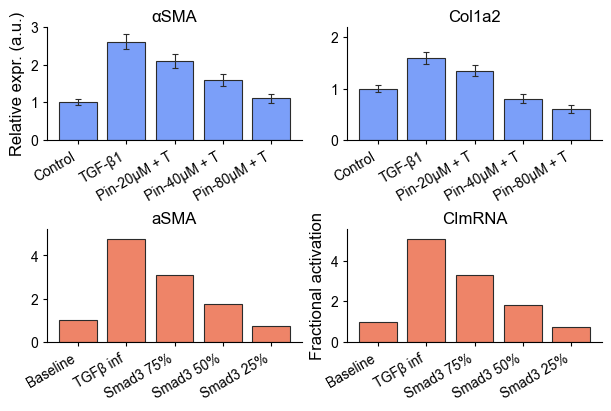

In [43]:
# ------------------------------------------------
# SAVE FOLDER
# ------------------------------------------------
fig_dir = "Figures_modelExp"
os.makedirs(fig_dir, exist_ok=True)

# ------------------------------------------------
# COLORS / STYLE
# ------------------------------------------------
# EXP_FACE   = "#f7f7f7"   # experimental bars
# MODEL_FACE = "#a9cddd"   # model bars
EDGE       = "#2b2b2b"

BAR_LW   = 0.8
ERR_LW   = 0.8
CAPSIZE  = 2.5
WIDTH    = 0.78

# ------------------------------------------------
# HELPER FUNCTIONS
# ------------------------------------------------
def style_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.tick_params(axis="both", width=0.8, length=3)
    ax.grid(False)
    ax.set_axisbelow(True)

def draw_bar_panel(ax, means, labels, title="",
                   ylabel=None, ylim=None,
                   facecolor="#ffffff", sems=None,
                   rotation=30):
    x = np.arange(len(means))
    means = np.asarray(means, dtype=float)

    ax.bar(
        x, means, width=WIDTH,
        color=facecolor,
        edgecolor=EDGE,
        linewidth=BAR_LW,
        zorder=2
    )

    if sems is not None:
        sems = np.asarray(sems, dtype=float)
        ax.errorbar(
            x, means, yerr=sems, fmt="none",
            ecolor=EDGE,
            elinewidth=ERR_LW,
            capsize=CAPSIZE,
            capthick=ERR_LW,
            zorder=3
        )

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=rotation, ha="right")
    ax.set_title(title, pad=4)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)

    style_axis(ax)



# Function to model Smad3 inhibition with TGFB infusion at different ymax levels
# (keeping your original logic, even though the earlier comment said Akt)
def model_Smad3_inhibition(ymax_Smad3_inh):
    ymax_inh = ymax.copy()
    ymax_inh[smad3] = ymax_Smad3_inh

    y0_local = y0.copy()
    y0_local[infusionTGFB] = bv + pv

    results_inh = run_model_real(EC50, n, y0_local, ymax_inh, w_vec)
    return results_inh

# inhibition levels
ymax_Smad3_levels = [75, 50, 25]   # percentage of Smad3 activity
results_Smad3_inhibition = [model_Smad3_inhibition(level / 100) for level in ymax_Smad3_levels]

# time point
t_target = 100.0
t_idx = int(np.argmin(np.abs(t - t_target)))
print(f"Panel C bars use t[{t_idx}] = {t[t_idx]:.2f}")

# species to plot
model_species = [CImRNA, aSMA, fibronectin]
model_titles  = ["CImRNA", "aSMA", "FN"]
model_ylabels = ["CImRNA Fractional Activation", "aSMA Fractional Activation", "FN Fractional Activation"]

model_labels = ["Baseline", "TGFβ inf", "Smad3 75%", "Smad3 50%", "Smad3 25%"]

def normalized_values(species_idx):
    base = baseline_results[t_idx, species_idx]
    return [
        baseline_results[t_idx, species_idx] / base,
        TGFBinfusion_results[t_idx, species_idx] / base,
        results_Smad3_inhibition[0][t_idx, species_idx] / base,
        results_Smad3_inhibition[1][t_idx, species_idx] / base,
        results_Smad3_inhibition[2][t_idx, species_idx] / base,
    ]

model_vals_CImRNA = normalized_values(CImRNA)
model_vals_aSMA   = normalized_values(aSMA)
model_vals_FN     = normalized_values(fibronectin)

# ============================================================
# 2) EXPERIMENTAL DATA
# ============================================================

exp_labels = ["Control", "TGF-β1", "Pin-20μM + T", "Pin-40μM + T", "Pin-80μM + T"]

# Relative expression of αSMA
means_asma = [1.00, 2.60, 2.10, 1.60, 1.10]
sems_asma  = [0.08, 0.20, 0.18, 0.16, 0.12]

# Relative expression of Col1a2
means_col1a2 = [1.00, 1.60, 1.35, 0.80, 0.60]
sems_col1a2  = [0.07, 0.12, 0.10, 0.09, 0.08]

# Relative expression of FN
means_fn = [1.00, 2.20, 1.60, 1.50, 1.35]
sems_fn  = [0.06, 0.15, 0.12, 0.11, 0.10]

# ============================================================
# 3) FIGURE
# 2 rows × 3 columns to match your draft organization
# ============================================================
b3=4
fig, axes = plt.subplots(
    2, 2,
    figsize=(6.0, b3),
    constrained_layout=True
)

# -------------------------
# Top row: experiment
# -------------------------
draw_bar_panel(
    axes[0, 0],
    means_asma,
    labels=exp_labels,
    title="αSMA",
    ylabel="Relative expr. (a.u.)",
    ylim=(0, 3.0),
    facecolor=EXP_FACE,
    sems=sems_asma,
    rotation=30
)

draw_bar_panel(
    axes[0, 1],
    means_col1a2,
    labels=exp_labels,
    title="Col1a2",
    ylabel=None,
    ylim=(0, 2.2),
    facecolor=EXP_FACE,
    sems=sems_col1a2,
    rotation=30
)

# draw_bar_panel(
#     axes[0, 2],
#     means_fn,
#     labels=exp_labels,
#     title="FN",
#     ylabel=None,
#     ylim=(0, 2.6),
#     facecolor=EXP_FACE,
#     sems=sems_fn,
#     rotation=30
# )

# -------------------------
# Bottom row: model
# -------------------------

draw_bar_panel(
    axes[1, 0],
    model_vals_aSMA,
    labels=model_labels,
    title="aSMA",
    # ylabel="Fractional activation",
    ylim=(0, max(model_vals_aSMA) * 1.10),
    facecolor=MODEL_FACE,
    sems=None,
    rotation=30
)


draw_bar_panel(
    axes[1, 1],
    model_vals_CImRNA,
    labels=model_labels,
    title="CImRNA",
    ylabel="Fractional activation",
    ylim=(0, max(model_vals_CImRNA) * 1.10),
    facecolor=MODEL_FACE,
    sems=None,
    rotation=30
)

# draw_bar_panel(
#     axes[1, 2],
#     model_vals_FN,
#     labels=model_labels,
#     title="FN",
#     # ylabel="Fractional activation",
#     ylim=(0, max(model_vals_FN) * 1.10),
#     facecolor=MODEL_FACE,
#     sems=None,
#     rotation=30
# )

# ============================================================
# SAVE
# ============================================================
plt.savefig(f"{fig_dir}/panel_C_standardized.png", bbox_inches="tight", dpi=600)
# plt.savefig(f"{fig_dir}/panel_C_standardized.pdf", bbox_inches="tight")
plt.show()

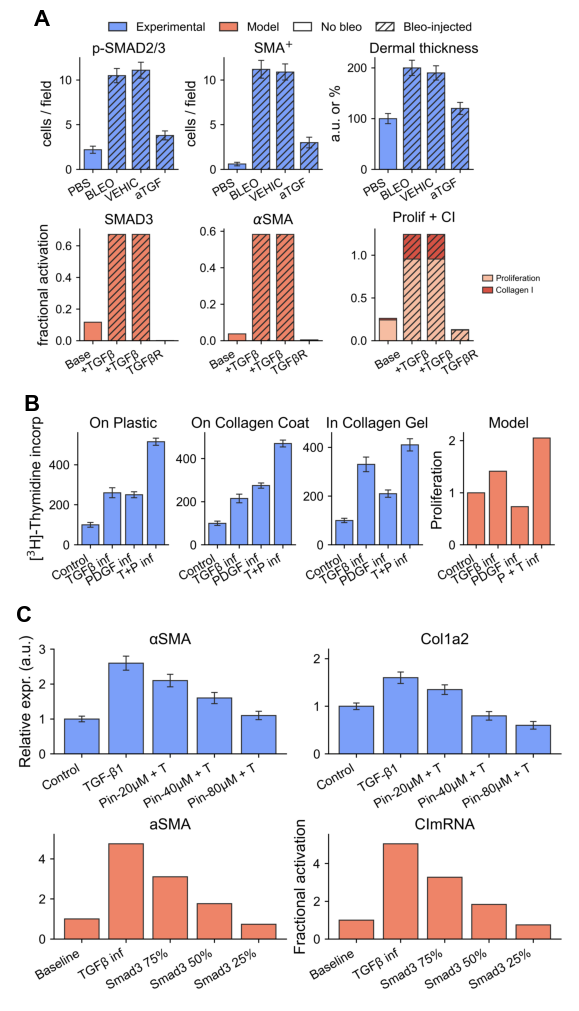

In [44]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# ------------------------------------------------
# Folder and file names
# ------------------------------------------------
fig_dir = "Figures_modelExp"

file_A = os.path.join(fig_dir, "panel_A_standardized.png")
file_B = os.path.join(fig_dir, "panel_B_standardized.png")
file_C = os.path.join(fig_dir, "panel_C_standardized.png")

# ------------------------------------------------
# Load images
# ------------------------------------------------
img_A = mpimg.imread(file_A)
img_B = mpimg.imread(file_B)
img_C = mpimg.imread(file_C)

# ------------------------------------------------
# Create combined figure
# ------------------------------------------------
btot=b1+b2+b3
fig, axes = plt.subplots(
    3, 1,
    figsize=(6, btot),   # adjust if you want taller/shorter
    gridspec_kw={"height_ratios": [1, 0.5, 1]}, # adjust if you want different relative heights
    constrained_layout=True
)

# Show images
axes[0].imshow(img_A)
axes[1].imshow(img_B)
axes[2].imshow(img_C)

# Remove axes
for ax in axes:
    ax.axis("off")

# ------------------------------------------------
# Add panel labels
# ------------------------------------------------
axes[0].text(
    0.01, 1, "A",
    transform=axes[0].transAxes,
    fontsize=16, fontweight="bold",
    va="top", ha="left"
)

axes[1].text(
    0.01, 1.08, "B",
    transform=axes[1].transAxes,
    fontsize=16, fontweight="bold",
    va="top", ha="left"
)

axes[2].text(
    0.01, 1.05, "C",
    transform=axes[2].transAxes,
    fontsize=16, fontweight="bold",
    va="top", ha="left"
)

# ------------------------------------------------
# Save combined figure
# ------------------------------------------------
out_png = os.path.join(fig_dir, "combined_ABC_c.png")
# out_pdf = os.path.join(fig_dir, "combined_ABC.pdf")

plt.savefig(out_png, dpi=600, bbox_inches="tight")
# plt.savefig(out_pdf, bbox_inches="tight")
plt.show()